In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [5]:
from google.colab import files

uploaded = files.upload()

Saving data.zip to data.zip


In [6]:
import zipfile
import os

with zipfile.ZipFile("data.zip", "r") as zip_ref:
    zip_ref.extractall("/content/QuickCart_Stockout_Project")

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [10]:
import os

print(os.listdir("/content"))

['.config', 'fact_inventory_daily.csv', 'data.zip', 'dim_events.csv', 'dim_events (1).csv', 'dim_stores.csv', 'dim_events (2).csv', 'dim_skus.csv', 'QuickCart_Stockout_Project', 'dim_suppliers.csv', 'sample_data']


In [11]:
for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))


/content/fact_inventory_daily.csv
/content/dim_events.csv
/content/dim_events (1).csv
/content/dim_stores.csv
/content/dim_events (2).csv
/content/dim_skus.csv
/content/dim_suppliers.csv
/content/QuickCart_Stockout_Project/fact_inventory_daily.csv
/content/QuickCart_Stockout_Project/dim_events.csv
/content/QuickCart_Stockout_Project/dim_stores.csv
/content/QuickCart_Stockout_Project/dim_skus.csv
/content/QuickCart_Stockout_Project/dim_suppliers.csv
/content/sample_data/mnist_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/california_housing_train.csv


In [12]:
import os
import pandas as pd

def find_file(filename):
    for root, dirs, files in os.walk("/content"):
        if filename in files:
            return os.path.join(root, filename)

    raise FileNotFoundError(
        f"{filename} not found. Please upload the dataset."
    )

stores = pd.read_csv(find_file("dim_stores.csv"))
skus = pd.read_csv(find_file("dim_skus.csv"))
suppliers = pd.read_csv(find_file("dim_suppliers.csv"))
events = pd.read_csv(find_file("dim_events.csv"))
inventory = pd.read_csv(find_file("fact_inventory_daily.csv"))

print("All five datasets loaded successfully!")

print("Stores:", stores.shape)
print("SKUs:", skus.shape)
print("Suppliers:", suppliers.shape)
print("Events:", events.shape)
print("Inventory:", inventory.shape)

All five datasets loaded successfully!
Stores: (12, 8)
SKUs: (60, 9)
Suppliers: (15, 6)
Events: (30, 5)
Inventory: (21600, 16)


In [13]:
print("Inventory Dataset")
display(inventory.head())

Inventory Dataset


,date,store_id,sku_id,supplier_id,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,reorder_placed,lead_time_days_expected,lead_time_days_actual,sales_velocity_7d,days_of_cover,is_festival_week,stockout_risk
0,2026-10-01,ST01,SKU001,SUP11,159.9,15,15.0,144.9,36.4,N,1,NaN,15.00,9.66,N,Safe
1,2026-10-02,ST01,SKU001,SUP11,144.9,10,10.0,134.9,36.4,N,1,NaN,12.50,10.79,N,Safe
2,2026-10-03,ST01,SKU001,SUP11,134.9,15,15.0,119.9,36.4,N,1,NaN,13.33,8.99,N,Safe
3,2026-10-04,ST01,SKU001,SUP11,119.9,10,10.0,109.9,36.4,N,1,NaN,12.50,8.79,N,Safe
4,2026-10-05,ST01,SKU001,SUP11,109.9,9,9.0,100.9,36.4,N,1,NaN,11.80,8.55,N,Safe


In [14]:
print(inventory.columns.tolist())

['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk']


In [15]:
print(inventory.isnull().sum())

date                           0
store_id                       0
sku_id                         0
supplier_id                    0
opening_stock                  0
units_demanded                 0
units_sold                     0
closing_stock                  0
reorder_point                  0
reorder_placed                 0
lead_time_days_expected        0
lead_time_days_actual      19899
sales_velocity_7d              0
days_of_cover                  0
is_festival_week               0
stockout_risk                  0
dtype: int64


In [16]:
print("Duplicate records:", inventory.duplicated().sum())

Duplicate records: 0


In [17]:
print(inventory["stockout_risk"].value_counts())

stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64


In [18]:
print(
    inventory["stockout_risk"]
    .value_counts(normalize=True) * 100
)

stockout_risk
Safe        65.421296
At-Risk     24.009259
Imminent    10.569444
Name: proportion, dtype: float64


In [19]:
stores["city_display"] = (
    stores["city_display"]
    .str.strip()
    .str.title()
)

In [20]:
suppliers["reliability_score"] = pd.to_numeric(
    suppliers["reliability_score"],
    errors="coerce"
)

In [21]:
median_value = suppliers["reliability_score"].median()

suppliers["reliability_score"] = (
    suppliers["reliability_score"].fillna(median_value)
)

In [22]:
print(suppliers["reliability_score"].isnull().sum())

0


In [23]:
inventory["date"] = pd.to_datetime(inventory["date"])
events["date"] = pd.to_datetime(events["date"])

In [24]:
df = inventory.merge(
    stores,
    on="store_id",
    how="left"
)

df = df.merge(
    skus,
    on="sku_id",
    how="left",
    suffixes=("", "_sku")
)

df = df.merge(
    suppliers,
    on="supplier_id",
    how="left",
    suffixes=("", "_supplier")
)

df = df.merge(
    events,
    on="date",
    how="left"
)

print("Final Dataset Shape:", df.shape)

display(df.head())

Final Dataset Shape: (21600, 40)


,date,store_id,sku_id,supplier_id,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,reorder_placed,...,supplier_id_sku,supplier_name,categories_supplied,reliability_score,base_lead_time_days,lead_time_variance_days,event_name,event_type,demand_multiplier_festive,demand_multiplier_other
0,2026-10-01,ST01,SKU001,SUP11,159.9,15,15.0,144.9,36.4,N,...,SUP11,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
1,2026-10-02,ST01,SKU001,SUP11,144.9,10,10.0,134.9,36.4,N,...,SUP11,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
2,2026-10-03,ST01,SKU001,SUP11,134.9,15,15.0,119.9,36.4,N,...,SUP11,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
3,2026-10-04,ST01,SKU001,SUP11,119.9,10,10.0,109.9,36.4,N,...,SUP11,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
4,2026-10-05,ST01,SKU001,SUP11,109.9,9,9.0,100.9,36.4,N,...,SUP11,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0


In [25]:
print("Total rows:", len(df))
print("Total columns:", len(df.columns))

Total rows: 21600
Total columns: 40


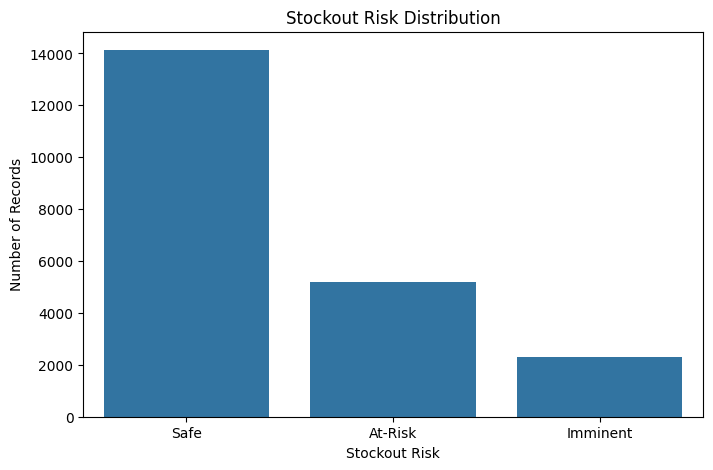

In [26]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="stockout_risk",
    order=["Safe", "At-Risk", "Imminent"]
)

plt.title("Stockout Risk Distribution")
plt.xlabel("Stockout Risk")
plt.ylabel("Number of Records")

plt.show()

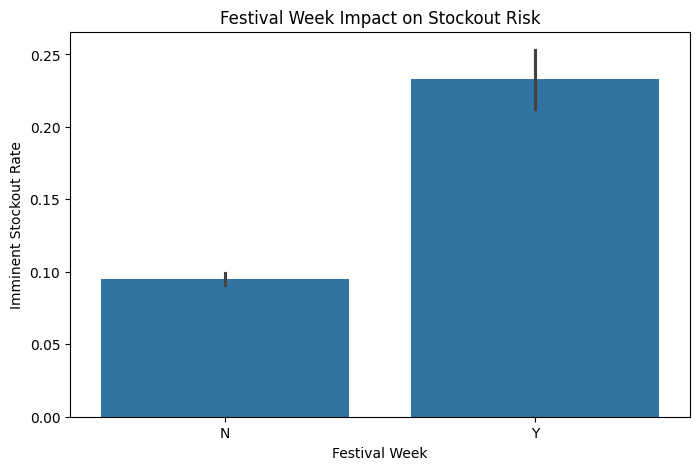

In [27]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x="is_festival_week",
    y=df["stockout_risk"].eq("Imminent").astype(int)
)

plt.title("Festival Week Impact on Stockout Risk")
plt.xlabel("Festival Week")
plt.ylabel("Imminent Stockout Rate")

plt.show()

In [28]:
df["reliability_group"] = pd.cut(
    df["reliability_score"],
    bins=[-np.inf, 0.75, 0.85, np.inf],
    labels=["Low", "Mid", "High"]
)

reliability_analysis = df.groupby(
    "reliability_group",
    observed=False
)["stockout_risk"].apply(
    lambda x: (x == "Imminent").mean() * 100
)

print(reliability_analysis)

reliability_group
Low     13.074495
Mid      3.263889
High     3.819444
Name: stockout_risk, dtype: float64


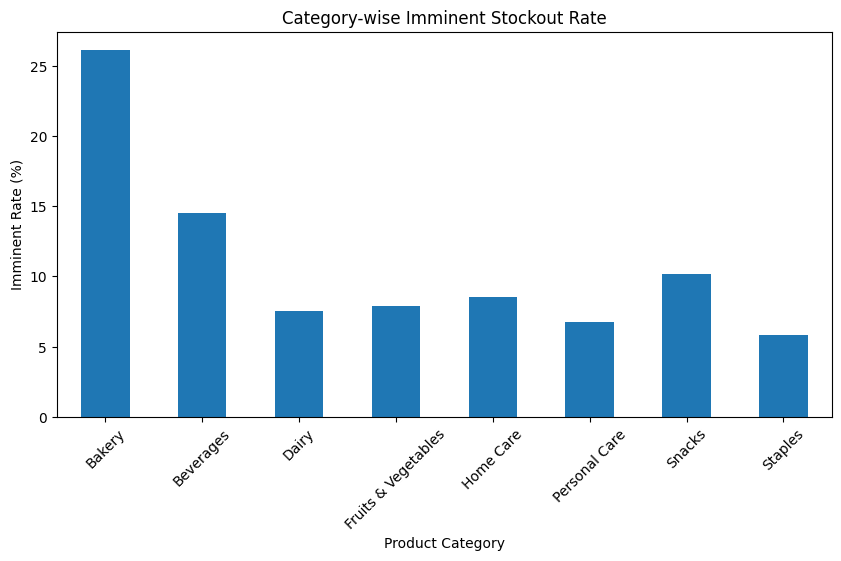

In [29]:
category_analysis = df.groupby(
    "category"
)["stockout_risk"].apply(
    lambda x: (x == "Imminent").mean() * 100
)

category_analysis.plot(
    kind="bar",
    figsize=(10,5),
    title="Category-wise Imminent Stockout Rate"
)

plt.ylabel("Imminent Rate (%)")
plt.xlabel("Product Category")
plt.xticks(rotation=45)
plt.show()

In [30]:
df["reorder_gap"] = (
    df["reorder_point"] - df["closing_stock"]
)

In [31]:
df["days_of_cover_ratio"] = (
    df["days_of_cover"] /
    df["lead_time_days_expected"].replace(0, np.nan)
)

In [32]:
df["day_of_month"] = df["date"].dt.day

df["month"] = df["date"].dt.month

df["day_of_week"] = df["date"].dt.dayofweek

In [33]:
df = df.sort_values(
    ["store_id", "sku_id", "date"]
).reset_index(drop=True)

df["reorder_flag"] = (
    df["reorder_placed"].map({"Y": 1, "N": 0})
)

df["is_recent_reorder"] = (
    df.groupby(["store_id", "sku_id"])["reorder_flag"]
    .transform(
        lambda x: x.shift(1).rolling(3, min_periods=1).max()
    )
    .fillna(0)
)

In [34]:
display(
    df[[
        "reorder_gap",
        "days_of_cover_ratio",
        "day_of_month",
        "is_recent_reorder"
    ]].head()
)

,reorder_gap,days_of_cover_ratio,day_of_month,is_recent_reorder
0,-108.5,9.66,1,0.0
1,-98.5,10.79,2,0.0
2,-83.5,8.99,3,0.0
3,-73.5,8.79,4,0.0
4,-64.5,8.55,5,0.0


In [36]:
numeric_features = [
    "opening_stock",
    "closing_stock",
    "units_sold",
    "units_demanded",
    "reorder_point",
    "lead_time_days_expected",
    "sales_velocity_7d",
    "days_of_cover",
    "reorder_gap",
    "days_of_cover_ratio",
    "reliability_score",
    "base_lead_time_days",
    "lead_time_variance_days",
    "unit_price_inr",
    "shelf_life_days",
    "sqft",
    "baseline_daily_orders",
    "demand_multiplier_festive",
    "demand_multiplier_other",
    "day_of_month",
    "day_of_week",
    "is_recent_reorder"
]

categorical_features = [
    "category",
    "store_size",
    "city",
    "popularity_tier",
    "event_type",
    "is_perishable",
    "festive_relevant",
    "is_festival_week"
]

In [37]:
numeric_features = [
    c for c in numeric_features if c in df.columns
]

categorical_features = [
    c for c in categorical_features if c in df.columns
]

X = df[numeric_features + categorical_features]

y = df["stockout_risk"]

In [38]:
train_mask = df["date"] <= "2026-10-23"

X_train = X.loc[train_mask]
X_test = X.loc[~train_mask]

y_train = y.loc[train_mask]
y_test = y.loc[~train_mask]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 16560
Testing records: 5040


In [39]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [40]:
baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print(
    "Baseline Accuracy:",
    accuracy_score(y_test, baseline_predictions)
)

Baseline Accuracy: 0.6228174603174603


In [41]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression Results")

print(
    classification_report(
        y_test,
        logistic_predictions,
        zero_division=0
    )
)

Logistic Regression Results
              precision    recall  f1-score   support

     At-Risk       0.90      0.67      0.77      1126
    Imminent       0.68      0.92      0.78       775
        Safe       0.99      0.99      0.99      3139

    accuracy                           0.91      5040
   macro avg       0.86      0.86      0.85      5040
weighted avg       0.92      0.91      0.91      5040



In [42]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Results")

print(
    classification_report(
        y_test,
        rf_predictions,
        zero_division=0
    )
)

Random Forest Results
              precision    recall  f1-score   support

     At-Risk       0.81      0.93      0.87      1126
    Imminent       0.89      0.69      0.78       775
        Safe       1.00      1.00      1.00      3139

    accuracy                           0.94      5040
   macro avg       0.90      0.87      0.88      5040
weighted avg       0.94      0.94      0.93      5040



In [43]:
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, baseline_predictions),
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, rf_predictions)
    ]
})

display(results)

,Model,Accuracy
0,Baseline,0.622817
1,Logistic Regression,0.909722
2,Random Forest,0.936111


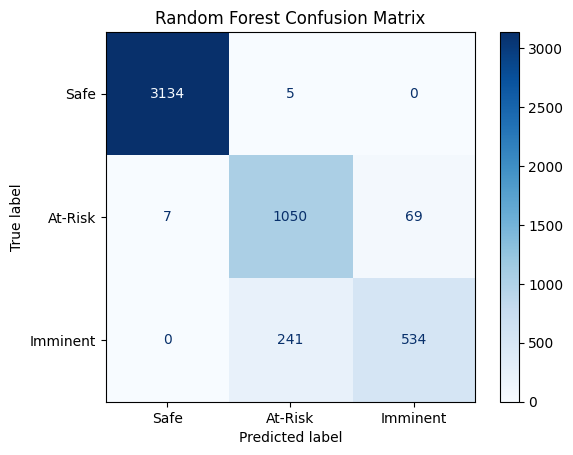

In [44]:
cm = confusion_matrix(
    y_test,
    rf_predictions,
    labels=["Safe", "At-Risk", "Imminent"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Safe", "At-Risk", "Imminent"]
)

disp.plot(cmap="Blues")

plt.title("Random Forest Confusion Matrix")
plt.show()

In [45]:
from sklearn.metrics import recall_score

imminent_recall = recall_score(
    y_test,
    rf_predictions,
    labels=["Imminent"],
    average=None,
    zero_division=0
)

print("Imminent Recall:", imminent_recall[0])

Imminent Recall: 0.6890322580645162


In [46]:
feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = (
    rf_model.named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
9,num__days_of_cover_ratio,0.219411
7,num__days_of_cover,0.218564
8,num__reorder_gap,0.178302
1,num__closing_stock,0.059304
0,num__opening_stock,0.030873
10,num__reliability_score,0.029012
6,num__sales_velocity_7d,0.026928
4,num__reorder_point,0.021063
5,num__lead_time_days_expected,0.017534
3,num__units_demanded,0.016912


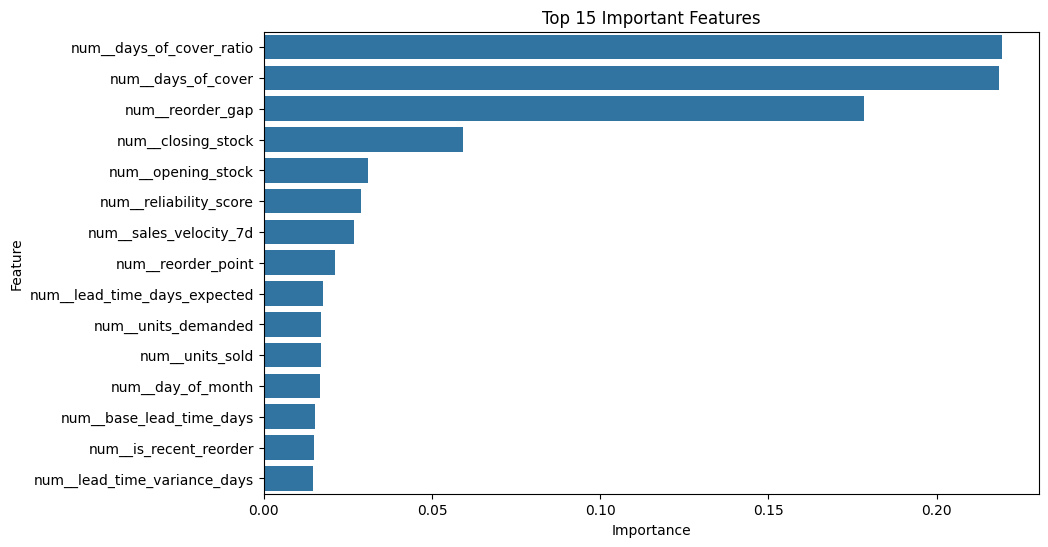

In [47]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")
plt.show()

In [48]:
sample = X_test.iloc[[0]]

prediction = rf_model.predict(sample)

print("Predicted Stockout Risk:", prediction[0])

Predicted Stockout Risk: At-Risk


In [49]:
print("Actual Stockout Risk:", y_test.iloc[0])

Actual Stockout Risk: At-Risk


In [50]:
import os

os.makedirs("outputs", exist_ok=True)

In [51]:
df.to_csv(
    "outputs/quickcart_final_dataset.csv",
    index=False
)

In [52]:
results.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

In [53]:
import joblib

joblib.dump(
    rf_model,
    "outputs/random_forest_model.pkl"
)

['outputs/random_forest_model.pkl']

In [56]:
from google.colab import files

files.download("outputs/model_comparison.csv")
files.download("outputs/random_forest_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>